# Release region

In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.io.shapereader as shpreader
from shapely.geometry import Polygon, box as sbox
from shapely.ops import unary_union
from matplotlib.path import Path as MplPath

In [2]:
# --- GLORYS12 / NEMO mesh ---
pathUVW = '/work/bk1450/b383184/Amazon/Mercator/data/variables/'
Hgr     = '/work/bk1450/b383184/Amazon/Mercator/data/Hgr_cmesh.nc'
Zgr     = '/work/bk1450/b383184/Amazon/Mercator/data/Zgr_cmesh2.nc'

# map window, reused everywhere
EXTENT = [-52, -46, -3, 4]

In [3]:
# --- NEW: green release band ---
#   A  Amazon coast  - start of the old release line
#   B  Para coast    - old line prolonged SE until it strikes the Para bank
#   B' seaward corner off B  (pushed NE, not perpendicular: the Maranhao coast
#                             bends east, so a perpendicular corner runs aground)
#   A' seaward corner off A  (0.8 deg perpendicular)
green_lons = [-49.916, -48.392, -47.8, -49.250, -49.916]
green_lats = [  1.166,  -1.05,  -0.6,   1.610,    1.166]

## Bathymetry from GLORYS12v1

In [4]:
hgr = xr.open_dataset(Hgr)
zgr = xr.open_dataset(Zgr)

lon2d = hgr['glamt'].isel(t=0).values          # T-point longitudes (y, x)
lat2d = hgr['gphit'].isel(t=0).values          # T-point latitudes  (y, x)
mbathy = zgr['mbathy'].isel(t=0).values        # wet-level count, 0 = land
deptht = zgr['deptht'].isel(t=0).values        # bottom depth at T points [m]

# --- clip to the map window -------------------------------------------------
pad = 0.5
inbox = ((lon2d >= EXTENT[0] - pad) & (lon2d <= EXTENT[1] + pad) &
         (lat2d >= EXTENT[2] - pad) & (lat2d <= EXTENT[3] + pad))
yi, xi = np.where(inbox)
ys, ye = yi.min(), yi.max() + 1
xs, xe = xi.min(), xi.max() + 1
sl = (slice(ys, ye), slice(xs, xe))

lon_s, lat_s = lon2d[sl], lat2d[sl]
mb_s, dp_s   = mbathy[sl], deptht[sl]

# --- model bathymetry: masked on land ---------------------------------------
land_mask = (mb_s == 0)
bathy = np.where(land_mask, np.nan, dp_s)

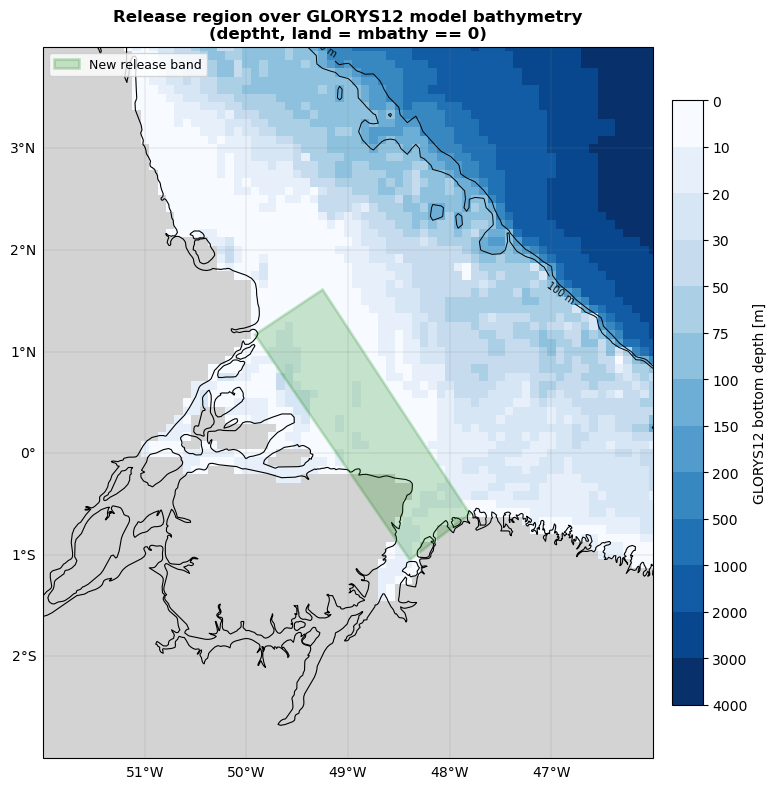

In [5]:
fig, ax = plt.subplots(figsize=(10, 8), subplot_kw=dict(projection=ccrs.PlateCarree()))
ax.set_extent(EXTENT, crs=ccrs.PlateCarree())

# log-ish depth scale: the shelf detail near the mouth is what matters here
levels = [0, 10, 20, 30, 50, 75, 100, 150, 200, 500, 1000, 2000, 3000, 4000]
norm = mcolors.BoundaryNorm(levels, ncolors=256)

pc = ax.pcolormesh(lon_s, lat_s, bathy, transform=ccrs.PlateCarree(),
                   cmap='Blues', norm=norm, shading='auto', zorder=0)

# model land mask (mbathy == 0), drawn from the model grid itself
ax.pcolormesh(lon_s, lat_s, np.where(land_mask, 1.0, np.nan),
              transform=ccrs.PlateCarree(), cmap=mcolors.ListedColormap(['lightgray']),
              shading='auto', zorder=1)

# 100 m and 200 m shelf-break isobaths
cs = ax.contour(lon_s, lat_s, bathy, levels=[100, 200], colors='k',
                linewidths=0.7, transform=ccrs.PlateCarree(), zorder=2)
ax.clabel(cs, fmt='%d m', fontsize=7)

ax.add_feature(cfeature.COASTLINE, linewidth=0.8, zorder=3)

gl = ax.gridlines(draw_labels=True, linewidth=0.3, color='gray', alpha=0.5)
gl.top_labels = False
gl.right_labels = False

ax.fill(green_lons, green_lats, transform=ccrs.PlateCarree(),
        facecolor='green', alpha=0.20, edgecolor='green', linewidth=2, zorder=4,
        label='New release band')
# ax.plot(old_lons, old_lats, transform=ccrs.PlateCarree(),
#         color='blue', linewidth=2, linestyle='--', zorder=4, label='Old release line')
# ax.plot(polygon_lons, polygon_lats, transform=ccrs.PlateCarree(),
#         color='red', linewidth=1.2, linestyle=':', zorder=4, label='Coles-style box')

cb = plt.colorbar(pc, ax=ax, orientation='vertical', pad=0.02, shrink=0.85,
                  ticks=levels)
cb.set_label('GLORYS12 bottom depth [m]')
cb.ax.invert_yaxis()

ax.legend(loc='upper left', fontsize=9)
ax.set_title('Release region over GLORYS12 model bathymetry\n'
             '(deptht, land = mbathy == 0)', fontsize=12, fontweight='bold')
plt.tight_layout()
# plt.savefig('release_polygon_bathymetry_glorys.png', dpi=200, bbox_inches='tight')
plt.show()

valid: True, area: 1.778 deg^2, 8 vertices


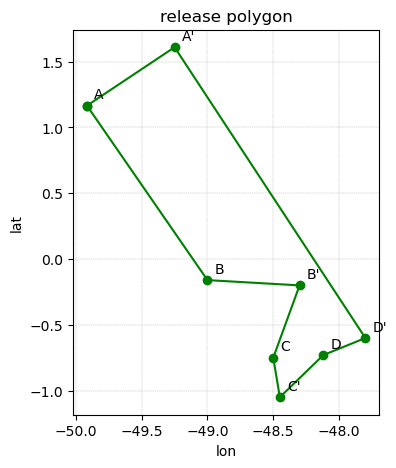

In [6]:
# --- release polygon (editable version) ---
# Define each corner by name. Edit any (lon, lat) below to move that edge.
# Order matters: vertices are connected in sequence, then the ring is closed.
from shapely.geometry import Polygon

vertices = {
    "A":  (-49.916,  1.166),   # Amazon coast  - start of release line
    "B":  (-49, -0.16),
    "B'": (-48.3,-0.2),
    "C":  (-48.5,-0.75),
    "C'": (-48.45,-1.05),
    "D":  (-48.12, -0.73 ),   # Para coast    - line prolonged SE to Para bank
    "D'": (-47.8,   -0.6  ),   # seaward corner off B (pushed NE)
    "A'": (-49.250,  1.610),   # seaward corner off A (0.8 deg perpendicular)
}

# build the closed ring (repeat the first point at the end)
_pts = list(vertices.values())
green_lons = [p[0] for p in _pts] + [_pts[0][0]]
green_lats = [p[1] for p in _pts] + [_pts[0][1]]

# quick validity check + preview
band = Polygon(zip(green_lons[:-1], green_lats[:-1]))
print(f"valid: {band.is_valid}, area: {band.area:.3f} deg^2, "
      f"{len(vertices)} vertices")

# optional: visualize before running the rest
import matplotlib.pyplot as plt
plt.figure(figsize=(5, 5))
plt.plot(green_lons, green_lats, "-o", color="green")
for name, (x, y) in vertices.items():
    plt.annotate(name, (x, y), textcoords="offset points", xytext=(5, 5))
plt.xlabel("lon"); plt.ylabel("lat"); plt.title("release polygon")
plt.grid(True, ls="--", lw=0.3); plt.gca().set_aspect("equal"); plt.show()

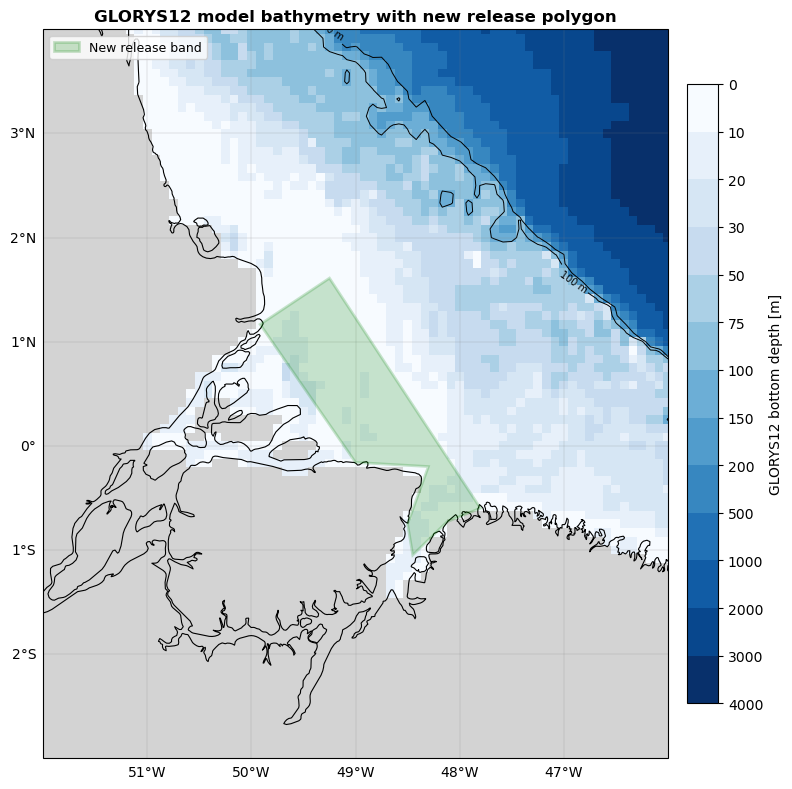

In [19]:
# --- full GLORYS12 bathymetry with the new release polygon on top ---
# Uses bathy / lon_s / lat_s / land_mask from cell [4] and green_lons/green_lats from cell [9].
fig, ax = plt.subplots(figsize=(10, 8), subplot_kw=dict(projection=ccrs.PlateCarree()))
ax.set_extent(EXTENT, crs=ccrs.PlateCarree())
levels = [0, 10, 20, 30, 50, 75, 100, 150, 200, 500, 1000, 2000, 3000, 4000]
norm = mcolors.BoundaryNorm(levels, ncolors=256)
pc = ax.pcolormesh(lon_s, lat_s, bathy, transform=ccrs.PlateCarree(), cmap='Blues', norm=norm, shading='auto', zorder=0)
ax.pcolormesh(lon_s, lat_s, np.where(land_mask, 1.0, np.nan), transform=ccrs.PlateCarree(), cmap=mcolors.ListedColormap(['lightgray']), shading='auto', zorder=1)
cs = ax.contour(lon_s, lat_s, bathy, levels=[100, 200], colors='k', linewidths=0.7, transform=ccrs.PlateCarree(), zorder=2)
ax.clabel(cs, fmt='%d m', fontsize=7)
ax.add_feature(cfeature.COASTLINE, linewidth=0.8, zorder=3)
gl = ax.gridlines(draw_labels=True, linewidth=0.3, color='gray', alpha=0.5)
gl.top_labels = False; gl.right_labels = False
ax.fill(green_lons, green_lats, transform=ccrs.PlateCarree(), facecolor='green', alpha=0.20, edgecolor='green', linewidth=2, zorder=4, label='New release band')
cb = plt.colorbar(pc, ax=ax, orientation='vertical', pad=0.02, shrink=0.85, ticks=levels)
cb.set_label('GLORYS12 bottom depth [m]'); cb.ax.invert_yaxis()
ax.legend(loc='upper left', fontsize=9)
ax.set_title('GLORYS12 model bathymetry with new release polygon', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()